# Quantitative Analysis of Portfolio Risk and Return

### Portfolio Optimization and Monte Carlo Simulation Using Python

---

**Research Question**

How does portfolio diversification across equities, technology stocks, gold, and bonds affect risk-adjusted returns under different market conditions?

**Assets:** SPY, QQQ, GLD, TLT

**Data Period:** 2015–2025

## 1. Introduction

Diversification is one of the fundamental concepts in portfolio management. 
By combining assets with different risk and return characteristics, investors 
may reduce portfolio risk.

In this project, Python is used to analyze four different assets:

- **SPY** — U.S. equities
- **QQQ** — technology and growth-oriented stocks
- **GLD** — gold
- **TLT** — long-term U.S. Treasury bonds

The analysis examines historical returns, volatility, correlations, 
portfolio risk, and risk-adjusted performance.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

## 2. Data Collection

Historical market data is collected using the Yahoo Finance database 
through the `yfinance` Python library.

The analysis uses daily adjusted prices from January 2015 to January 2026.

In [55]:
tickers = ["SPY", "QQQ", "GLD", "TLT"]

data = yf.download(
    tickers,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True
)

data.head()

[*********************100%***********************]  4 of 4 completed


Price            Close                                          High  \
Ticker             GLD        QQQ         SPY        TLT         GLD   
Date                                                                   
2015-01-02  114.080002  94.462685  169.267502  91.566475  114.800003   
2015-01-05  115.800003  93.077057  166.210632  93.004807  116.000000   
2015-01-06  117.120003  91.829056  164.645096  94.680489  117.500000   
2015-01-07  116.430000  93.012840  166.696701  94.493546  116.879997   
2015-01-08  115.940002  94.793068  169.654785  93.242172  116.870003   

Price                                                Low             \
Ticker            QQQ         SPY        TLT         GLD        QQQ   
Date                                                                  
2015-01-02  95.618916  170.462264  91.811000  112.320000  94.003861   
2015-01-05  94.159882  168.394140  93.227752  114.730003  92.810938   
2015-01-06  93.370705  167.034595  95.284611  115.800003  91.416117   
2015-01-07  93.233074  167.034530  94.910673  116.169998  92.214484   
2015-01-08  94.976595  169.869025  93.759985  115.849998  93.701064   

Price                                    Open                         \
Ticker             SPY        TLT         GLD        QQQ         SPY   
Date                                                                   
2015-01-02  168.237543  90.725031  112.489998  95.215156  170.050280   
2015-01-05  165.905769  92.026711  114.779999  94.049762  168.229349   
2015-01-06  163.854082  93.630487  116.220001  93.214707  166.515492   
2015-01-07  165.518435  93.616141  116.470001  92.434724  165.963371   
2015-01-08  168.081018  93.076763  116.449997  93.802006  168.097488   

Price                    Volume                                 
Ticker            TLT       GLD       QQQ        SPY       TLT  
Date                                                            
2015-01-02  90.825717   7109600  31314600  121465900   9432000  
2015-01-05  92.062667   8177400  36521300  169632600   9789500  
2015-01-06  93.997267  11238300  66205500  209151400  18331300  
2015-01-07  93.997307   6434200  37577400  125346700   9762900  
2015-01-08  93.752798   7033700  40212600  147217800   8055300

### Historical Closing Prices

For the analysis, adjusted closing prices are used because they account 
for relevant corporate actions and provide a consistent price series.

In [56]:
prices = data["Close"]

prices.head()

Ticker,GLD,QQQ,SPY,TLT
Date,,,,
2015-01-02,114.080002,94.462685,169.267502,91.566475
2015-01-05,115.800003,93.077057,166.210632,93.004807
2015-01-06,117.120003,91.829056,164.645096,94.680489
2015-01-07,116.430000,93.012840,166.696701,94.493546
2015-01-08,115.940002,94.793068,169.654785,93.242172


## 3. Return Analysis

### Daily Returns

Daily returns measure the percentage change in an asset's price 
from one trading day to the next.

The daily return is calculated as:

R(t)=P(t)-P(t-1)/P(t-1)

In [57]:
returns = prices.pct_change()

returns.head()

Ticker,GLD,QQQ,SPY,TLT
Date,,,,
2015-01-02,NaN,NaN,NaN,NaN
2015-01-05,0.015077,-0.014669,-0.018059,0.015708
2015-01-06,0.011399,-0.013408,-0.009419,0.018017
2015-01-07,-0.005891,0.012891,0.012461,-0.001974
2015-01-08,-0.004209,0.019140,0.017745,-0.013243


### Cumulative Returns

Cumulative returns show how an initial investment would have grown 
over the analyzed period.

For visualization, the initial investment is normalized to $1.

In [58]:
cumulative_returns = (1 + returns).cumprod()

cumulative_returns.head()

Ticker,GLD,QQQ,SPY,TLT
Date,,,,
2015-01-02,NaN,NaN,NaN,NaN
2015-01-05,1.015077,0.985331,0.981941,1.015708
2015-01-06,1.026648,0.972120,0.972692,1.034008
2015-01-07,1.020600,0.984652,0.984812,1.031967
2015-01-08,1.016304,1.003498,1.002288,1.018300


### Growth of $1

The following chart compares the growth of a hypothetical $1 investment 
in each asset over the analyzed period.

<Figure size 1200x600 with 0 Axes>

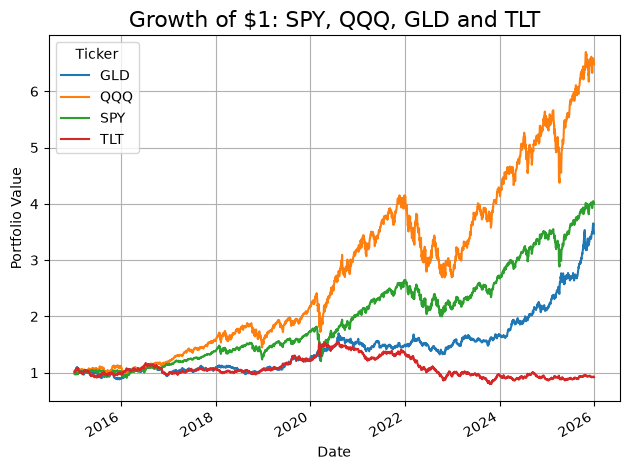

In [59]:
plt.figure(figsize=(12, 6))

cumulative_returns.plot()

plt.title("Growth of $1: SPY, QQQ, GLD and TLT", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.grid(True)
plt.tight_layout()

plt.show()

### Interpretation

The cumulative return chart allows us to compare the long-term growth 
of the four assets.

However, higher cumulative returns do not necessarily mean lower risk. 
Therefore, the next stage analyzes annual returns and volatility.

# 4. Risk and Return Analysis

Two important characteristics of each asset are examined:

- **Annual Return** — average annualized return
- **Annual Volatility** — measure of the variability of returns

Higher volatility indicates larger fluctuations in an asset's returns.

In [60]:
annual_returns = returns.mean() * 252

annual_returns

Ticker
GLD    0.124400
QQQ    0.194586
SPY    0.142186
TLT    0.003683
dtype: float64

In [61]:
annual_volatility = returns.std() * np.sqrt(252)

annual_volatility

Ticker
GLD    0.147472
QQQ    0.219817
SPY    0.177925
TLT    0.150397
dtype: float64

### Annual Return and Volatility

The following table summarizes the historical annualized return 
and volatility of each asset.

In [62]:
summary = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
})

summary

,Annual Return,Annual Volatility
Ticker,,
GLD,0.124400,0.147472
QQQ,0.194586,0.219817
SPY,0.142186,0.177925
TLT,0.003683,0.150397


## 5. Correlation Analysis

Correlation measures how two assets tend to move relative to each other.

The correlation coefficient ranges from -1 to +1:

- **+1** — assets move together
- **0** — little linear relationship
- **-1** — assets tend to move in opposite directions

Correlation is important because diversification can reduce portfolio risk 
when assets do not move closely together.

In [63]:
correlation_matrix = returns.corr()

correlation_matrix

Ticker,GLD,QQQ,SPY,TLT
Ticker,,,,
GLD,1.000000,0.052230,0.044217,0.280961
QQQ,0.052230,1.000000,0.933780,-0.131283
SPY,0.044217,0.933780,1.000000,-0.184989
TLT,0.280961,-0.131283,-0.184989,1.000000


### Correlation Heatmap

A heatmap provides a visual representation of the relationships 
between the assets.

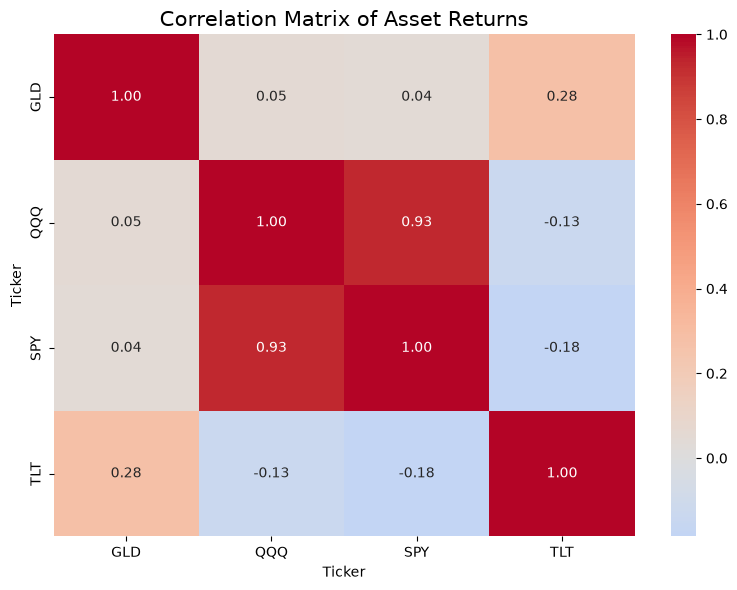

In [64]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of Asset Returns", fontsize=15)
plt.tight_layout()

plt.show()

### Interpretation

The correlation matrix shows that SPY and QQQ have a very high positive 
correlation, meaning that they tend to move in a similar direction.

In contrast, GLD has relatively low correlations with SPY and QQQ, 
while TLT has weak negative correlations with both equity assets.

These relationships are important for understanding the potential 
diversification benefits of combining the four assets.

# 6. Portfolio Analysis

The next step is to compare different portfolio structures.

Three portfolios are examined:

1. **100% SPY**
2. **50% SPY + 50% QQQ**
3. **25% SPY + 25% QQQ + 25% GLD + 25% TLT**

The goal is to examine how diversification changes portfolio return 
and volatility.

### Covariance Matrix

Covariance measures how two assets move together in absolute return terms.

The covariance matrix is required to calculate portfolio volatility.

In [65]:
covariance_matrix = returns.cov() * 252

covariance_matrix

Ticker,GLD,QQQ,SPY,TLT
Ticker,,,,
GLD,0.021748,0.001693,0.001160,0.006232
QQQ,0.001693,0.048320,0.036521,-0.004340
SPY,0.001160,0.036521,0.031657,-0.004950
TLT,0.006232,-0.004340,-0.004950,0.022619


## 7. Portfolio Comparison

### Portfolio 1 — 100% SPY

The first portfolio consists entirely of SPY and serves as a benchmark 
for comparing the effects of diversification.

In [66]:
weights_spy = np.array([0, 0, 1, 0])

### Portfolio Return

In [67]:
return_spy = np.dot(weights_spy, annual_returns)

return_spy

np.float64(0.14218636124918774)

### Portfolio Volatility

In [68]:
volatility_spy = np.sqrt(
    np.dot(
        weights_spy.T,
        np.dot(covariance_matrix, weights_spy)
    )
)

volatility_spy

np.float64(0.17792485293876825)

### Portfolio 2 — 50% SPY + 50% QQQ

The second portfolio combines two equity-oriented assets.
Because SPY and QQQ have a high positive correlation, this portfolio 
allows us to examine whether adding another equity asset substantially 
changes portfolio risk.

In [69]:
weights_spy_qqq = np.array([0, 0.5, 0.5, 0])

In [70]:
return_spy_qqq = np.dot(weights_spy_qqq, annual_returns)

return_spy_qqq

np.float64(0.16838629071829403)

In [71]:
volatility_spy_qqq = np.sqrt(
    np.dot(
        weights_spy_qqq.T,
        np.dot(covariance_matrix, weights_spy_qqq)
    )
)

volatility_spy_qqq

np.float64(0.19558821745495902)

### Portfolio 3 — Fully Diversified Portfolio

The third portfolio allocates equal weights to equities, technology 
stocks, gold, and bonds.

Each asset receives a 25% allocation.

In [72]:
weights = np.array([0.25, 0.25, 0.25, 0.25])

In [73]:
return_diversified = np.dot(weights, annual_returns)

return_diversified

np.float64(0.11621388311535327)

In [74]:
volatility_diversified = np.sqrt(
    np.dot(
        weights.T,
        np.dot(covariance_matrix, weights)
    )
)

volatility_diversified

np.float64(0.1109547147844276)

### Portfolio Performance Comparison

The three portfolio structures are compared based on their historical 
annual return and annual volatility.

In [75]:
portfolio_summary = pd.DataFrame({
    "Portfolio": [
        "100% SPY",
        "50% SPY + 50% QQQ",
        "25% GLD + 25% QQQ + 25% SPY + 25% TLT"
    ],
    "Annual Return": [
        return_spy,
        return_spy_qqq,
        return_diversified
    ],
    "Annual Volatility": [
        volatility_spy,
        volatility_spy_qqq,
        volatility_diversified
    ]
})

portfolio_summary

,Portfolio,Annual Return,Annual Volatility
0,100% SPY,0.142186,0.177925
1,50% SPY + 50% QQQ,0.168386,0.195588
2,25% GLD + 25% QQQ + 25% SPY + 25% TLT,0.116214,0.110955


In [76]:
portfolio_summary.style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}"
})

,Portfolio,Annual Return,Annual Volatility
0,100% SPY,14.22%,17.79%
1,50% SPY + 50% QQQ,16.84%,19.56%
2,25% GLD + 25% QQQ + 25% SPY + 25% TLT,11.62%,11.10%


### Interpretation

The 50/50 SPY and QQQ portfolio produced a higher historical return 
than the 100% SPY portfolio, but it also had higher volatility.

The fully diversified portfolio produced a lower historical return, 
but its volatility was substantially lower.

This suggests that diversification across assets with different 
correlations can reduce portfolio risk, although diversification 
does not necessarily increase absolute returns.

# 8. Risk-Adjusted Performance

### Sharpe Ratio

The Sharpe Ratio measures the return of a portfolio relative to its risk.

In this project, a simplified Sharpe Ratio is initially calculated using 
a 0% risk-free rate:

\[
Sharpe\ Ratio = \frac{R_p}{\sigma_p}
\]

where:

- \(R_p\) is the portfolio return
- \(\sigma_p\) is the portfolio volatility

In [77]:
sharpe_spy = return_spy / volatility_spy

sharpe_spy

np.float64(0.7991371576298018)

### Sharpe Ratio — 50% SPY + 50% QQQ

In [78]:
sharpe_spy_qqq = return_spy_qqq / volatility_spy_qqq

sharpe_spy_qqq

np.float64(0.8609224671576693)

### Sharpe Ratio — Diversified Portfolio

In [79]:
sharpe_diversified = return_diversified / volatility_diversified

sharpe_diversified

np.float64(1.0473992325710866)

### Risk-Adjusted Performance Comparison

The following table compares the three portfolios using return, 
volatility, and the simplified Sharpe Ratio.

In [80]:
sharpe_summary = pd.DataFrame({
    "Portfolio": [
        "100% SPY",
        "50% SPY + 50% QQQ",
        "25% GLD + 25% QQQ + 25% SPY + 25% TLT"
    ],
    "Annual Return": [
        return_spy,
        return_spy_qqq,
        return_diversified
    ],
    "Annual Volatility": [
        volatility_spy,
        volatility_spy_qqq,
        volatility_diversified
    ],
    "Sharpe Ratio": [
        sharpe_spy,
        sharpe_spy_qqq,
        sharpe_diversified
    ]
})

sharpe_summary

,Portfolio,Annual Return,Annual Volatility,Sharpe Ratio
0,100% SPY,0.142186,0.177925,0.799137
1,50% SPY + 50% QQQ,0.168386,0.195588,0.860922
2,25% GLD + 25% QQQ + 25% SPY + 25% TLT,0.116214,0.110955,1.047399


In [81]:
sharpe_summary.style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}"
})

,Portfolio,Annual Return,Annual Volatility,Sharpe Ratio
0,100% SPY,14.22%,17.79%,0.799
1,50% SPY + 50% QQQ,16.84%,19.56%,0.861
2,25% GLD + 25% QQQ + 25% SPY + 25% TLT,11.62%,11.10%,1.047


### Interpretation

The 50% SPY and 50% QQQ portfolio generated a higher historical return 
than the 100% SPY portfolio, but it also experienced higher volatility.

The diversified portfolio generated a lower historical return, but it 
had substantially lower volatility.

The diversified portfolio also produced the highest simplified Sharpe 
Ratio among the three portfolios. This indicates that, during the 
analyzed period, its historical return was higher relative to the 
amount of volatility taken.

The Sharpe Ratio does not measure absolute performance. It evaluates 
return relative to risk.

# 9. Portfolio Performance Under Different Market Conditions

Financial markets can behave very differently during different periods.

To investigate whether diversification provides consistent benefits, 
portfolio performance will be examined across different market conditions.

For this analysis, three periods are considered:

- **2015–2019** — pre-pandemic market period
- **2020–2021** — pandemic and strong recovery period
- **2022–2025** — period characterized by higher interest rates and changing market conditions

The purpose is not to predict future performance, but to examine how 
the portfolios behaved historically during different periods.

In [82]:
periods = {
    "2015-2019": ("2015-01-01", "2020-01-01"),
    "2020-2021": ("2020-01-01", "2022-01-01"),
    "2022-2025": ("2022-01-01", "2026-01-01")
}

periods

{'2015-2019': ('2015-01-01', '2020-01-01'),
 '2020-2021': ('2020-01-01', '2022-01-01'),
 '2022-2025': ('2022-01-01', '2026-01-01')}

### Defining the Analysis Periods

Python stores the beginning and ending dates of each period in a 
dictionary called `periods`.

This allows the same calculations to be applied consistently 
to each market period.

### Portfolio Calculation Function

A function is created to calculate annualized return and volatility 
for a given set of daily returns and portfolio weights.

In [83]:
def calculate_portfolio_metrics(period_returns, weights):
    portfolio_daily_returns = period_returns @ weights
    
    annual_return = portfolio_daily_returns.mean() * 252
    annual_volatility = portfolio_daily_returns.std() * np.sqrt(252)
    
    return annual_return, annual_volatility

In [84]:
test_return, test_volatility = calculate_portfolio_metrics(
    returns,
    weights
)

print("Annual Return:", test_return)
print("Annual Volatility:", test_volatility)

Annual Return: 0.11621388311535329
Annual Volatility: 0.11095471478442763


### Performance Across Market Periods

The three portfolios are evaluated separately during each historical 
period.

In [85]:
portfolio_weights = {
    "100% SPY": weights_spy,
    "50% SPY + 50% QQQ": weights_spy_qqq,
    "Diversified": weights
}

market_results = []

for period_name, (start_date, end_date) in periods.items():
    
    period_returns = returns.loc[start_date:end_date]
    
    for portfolio_name, portfolio_weight in portfolio_weights.items():
        
        annual_return, annual_volatility = calculate_portfolio_metrics(
            period_returns,
            portfolio_weight
        )
        
        market_results.append({
            "Period": period_name,
            "Portfolio": portfolio_name,
            "Annual Return": annual_return,
            "Annual Volatility": annual_volatility
        })

market_results = pd.DataFrame(market_results)

market_results

,Period,Portfolio,Annual Return,Annual Volatility
0,2015-2019,100% SPY,0.118817,0.134275
1,2015-2019,50% SPY + 50% QQQ,0.144208,0.150188
2,2015-2019,Diversified,0.096527,0.078028
3,2020-2021,100% SPY,0.242401,0.253327
4,2020-2021,50% SPY + 50% QQQ,0.300384,0.262665
5,2020-2021,Diversified,0.195140,0.140261
6,2022-2025,100% SPY,0.121016,0.180061
7,2022-2025,50% SPY + 50% QQQ,0.132227,0.206167
8,2022-2025,Diversified,0.101148,0.128129


In [86]:
market_results.style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}"
})

,Period,Portfolio,Annual Return,Annual Volatility
0,2015-2019,100% SPY,11.88%,13.43%
1,2015-2019,50% SPY + 50% QQQ,14.42%,15.02%
2,2015-2019,Diversified,9.65%,7.80%
3,2020-2021,100% SPY,24.24%,25.33%
4,2020-2021,50% SPY + 50% QQQ,30.04%,26.27%
5,2020-2021,Diversified,19.51%,14.03%
6,2022-2025,100% SPY,12.10%,18.01%
7,2022-2025,50% SPY + 50% QQQ,13.22%,20.62%
8,2022-2025,Diversified,10.11%,12.81%


# 10. Monte Carlo Simulation

Monte Carlo simulation is used to explore thousands of possible portfolio allocations.

In this project, random portfolio weights are generated for SPY, QQQ, GLD, and TLT. The annualized return, volatility, and Sharpe Ratio are calculated for each portfolio.

The goal is to identify portfolio allocations that offer attractive risk-adjusted returns based on historical data.

In [87]:
num_portfolios = 10000

In [88]:
results = []

portfolio_weights_list = []

In [89]:
for i in range(num_portfolios):
    random_weights = np.random.random(len(returns.columns))
    random_weights = random_weights / np.sum(random_weights)

    portfolio_return = np.dot(random_weights, annual_returns)

    portfolio_volatility = np.sqrt(
        np.dot(
            random_weights.T,
            np.dot(covariance_matrix, random_weights)
        )
    )

    portfolio_sharpe = portfolio_return / portfolio_volatility

    results.append([
        portfolio_return,
        portfolio_volatility,
        portfolio_sharpe
    ])

    portfolio_weights_list.append(random_weights)

In [90]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Annual Return",
        "Annual Volatility",
        "Sharpe Ratio"
    ]
)

results_df.head()

,Annual Return,Annual Volatility,Sharpe Ratio
0,0.105980,0.100688,1.052564
1,0.095478,0.103547,0.922068
2,0.111693,0.109592,1.019172
3,0.131400,0.117811,1.115343
4,0.078842,0.103393,0.762552


In [91]:
results_df.head().style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}"
})

,Annual Return,Annual Volatility,Sharpe Ratio
0,10.60%,10.07%,1.053
1,9.55%,10.35%,0.922
2,11.17%,10.96%,1.019
3,13.14%,11.78%,1.115
4,7.88%,10.34%,0.763


In [92]:
best_sharpe_index = results_df["Sharpe Ratio"].idxmax()

best_portfolio = results_df.loc[best_sharpe_index]

best_weights = portfolio_weights_list[best_sharpe_index]

print("Best Portfolio:")
print(best_portfolio)

print("\nPortfolio Weights:")
for ticker, weight in zip(returns.columns, best_weights):
    print(f"{ticker}: {weight:.2%}")

Best Portfolio:
Annual Return        0.152323
Annual Volatility    0.127896
Sharpe Ratio         1.190991
Name: 7902, dtype: float64

Portfolio Weights:
GLD: 57.61%
QQQ: 40.98%
SPY: 0.63%
TLT: 0.79%


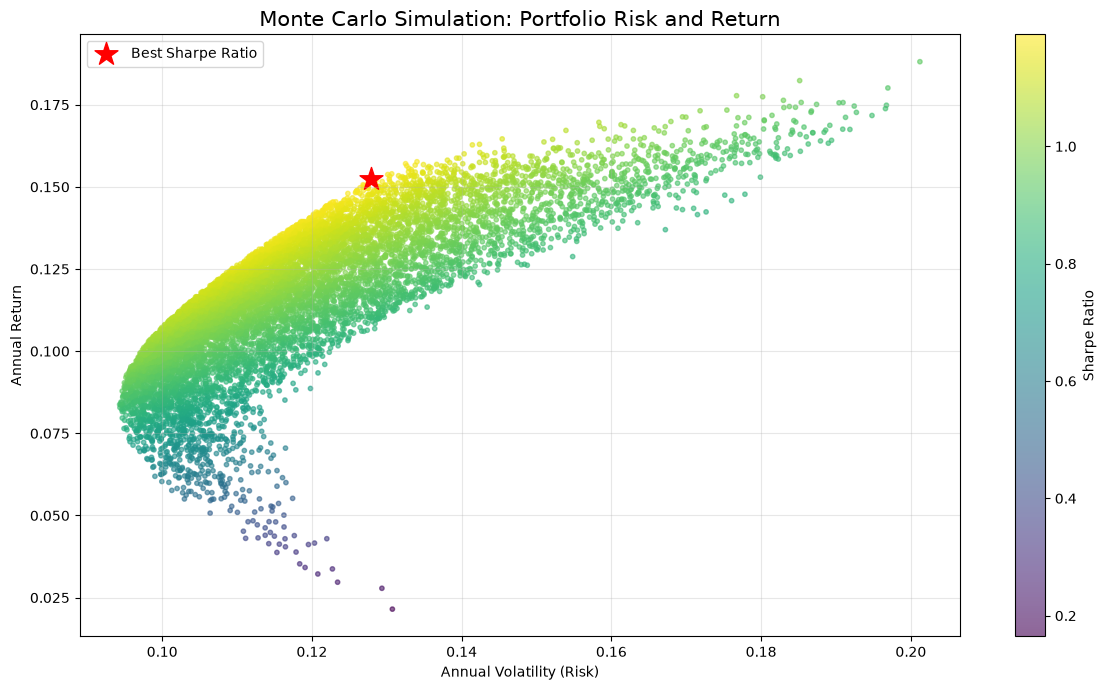

In [93]:
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    results_df["Annual Volatility"],
    results_df["Annual Return"],
    c=results_df["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.6,
    s=10
)

plt.colorbar(scatter, label="Sharpe Ratio")

plt.scatter(
    best_portfolio["Annual Volatility"],
    best_portfolio["Annual Return"],
    color="red",
    marker="*",
    s=300,
    label="Best Sharpe Ratio"
)

plt.title("Monte Carlo Simulation: Portfolio Risk and Return", fontsize=15)
plt.xlabel("Annual Volatility (Risk)")
plt.ylabel("Annual Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [94]:
comparison_df = pd.DataFrame({
    "Portfolio": [
        "100% SPY",
        "50% SPY + 50% QQQ",
        "Equal-Weight Portfolio",
        "Best Monte Carlo Portfolio"
    ],
    "Annual Return": [
        return_spy,
        return_spy_qqq,
        return_diversified,
        best_portfolio["Annual Return"]
    ],
    "Annual Volatility": [
        volatility_spy,
        volatility_spy_qqq,
        volatility_diversified,
        best_portfolio["Annual Volatility"]
    ],
    "Sharpe Ratio": [
        sharpe_spy,
        sharpe_spy_qqq,
        sharpe_diversified,
        best_portfolio["Sharpe Ratio"]
    ]
})

comparison_df.style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}"
})

,Portfolio,Annual Return,Annual Volatility,Sharpe Ratio
0,100% SPY,14.22%,17.79%,0.799
1,50% SPY + 50% QQQ,16.84%,19.56%,0.861
2,Equal-Weight Portfolio,11.62%,11.10%,1.047
3,Best Monte Carlo Portfolio,15.23%,12.79%,1.191


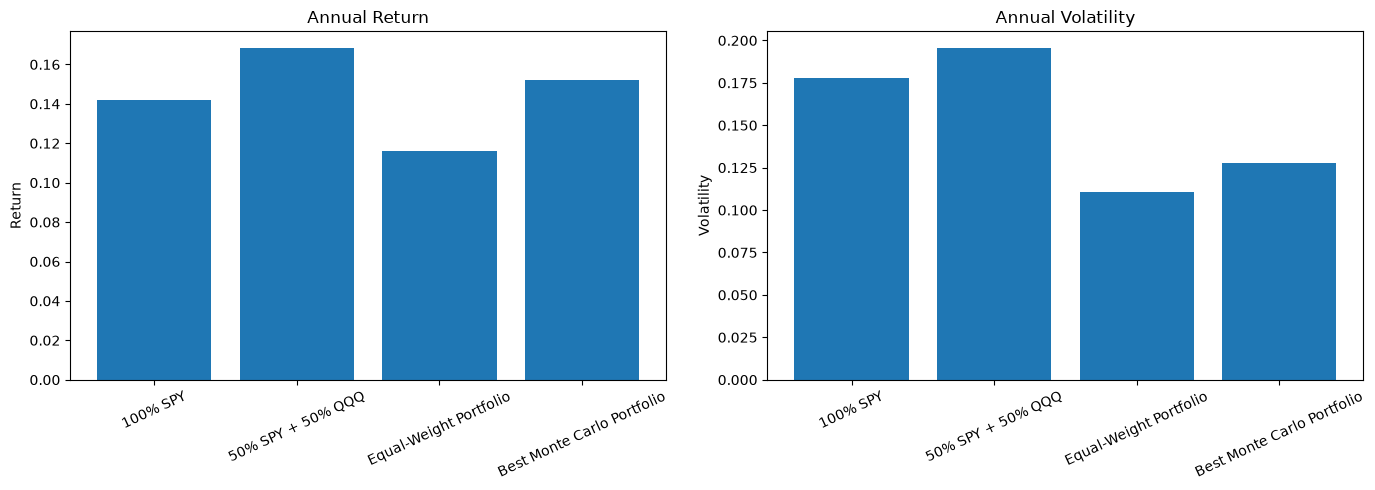

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    comparison_df["Portfolio"],
    comparison_df["Annual Return"]
)
axes[0].set_title("Annual Return")
axes[0].set_ylabel("Return")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(
    comparison_df["Portfolio"],
    comparison_df["Annual Volatility"]
)
axes[1].set_title("Annual Volatility")
axes[1].set_ylabel("Volatility")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [96]:
comparison_df.sort_values(
    by="Sharpe Ratio",
    ascending=False
).style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}"
})

,Portfolio,Annual Return,Annual Volatility,Sharpe Ratio
3,Best Monte Carlo Portfolio,15.23%,12.79%,1.191
2,Equal-Weight Portfolio,11.62%,11.10%,1.047
1,50% SPY + 50% QQQ,16.84%,19.56%,0.861
0,100% SPY,14.22%,17.79%,0.799


# 11. Conclusion

This project examined how diversification across equities, technology stocks, gold, and long-term government bonds affected historical portfolio risk and return.

The analysis compared three predefined portfolios and generated 10,000 random portfolio allocations using Monte Carlo simulation.

The results illustrate several important principles:

- Portfolios with higher historical returns may also experience higher volatility.
- Combining assets with different correlation patterns can reduce portfolio risk.
- The Sharpe Ratio helps compare historical returns relative to volatility.
- Monte Carlo simulation provides a way to explore a large number of possible portfolio allocations.

The best-performing simulated portfolio had the highest Sharpe Ratio among the randomly generated allocations. However, this result depends on the historical sample and does not guarantee superior future performance.

Overall, the project demonstrates how Python, statistical analysis, and portfolio theory can be combined to investigate financial risk and diversification.


## Limitations

This analysis has several limitations:

1. Historical returns and correlations may differ from future market conditions.
2. Transaction costs, taxes, and trading fees are not included.
3. The Sharpe Ratio is calculated using a simplified risk-free rate of 0%.
4. Monte Carlo simulation uses randomly generated portfolio weights, so it does not guarantee finding the globally optimal portfolio.
5. Annualized historical averages do not fully capture extreme market events or all aspects of downside risk.

Future improvements could include a realistic risk-free rate, portfolio optimization, maximum drawdown analysis, and out-of-sample testing.


In [97]:
print(comparison_df.to_string(index=False))

print("\nBest Portfolio Weights:")
for ticker, weight in zip(returns.columns, best_weights):
    print(f"{ticker}: {weight:.2%}")

                 Portfolio  Annual Return  Annual Volatility  Sharpe Ratio
                  100% SPY       0.142186           0.177925      0.799137
         50% SPY + 50% QQQ       0.168386           0.195588      0.860922
    Equal-Weight Portfolio       0.116214           0.110955      1.047399
Best Monte Carlo Portfolio       0.152323           0.127896      1.190991

Best Portfolio Weights:
GLD: 57.61%
QQQ: 40.98%
SPY: 0.63%
TLT: 0.79%


## Final Conclusion

This project investigated how diversification across U.S. equities, technology stocks, gold, and long-term government bonds affects historical portfolio risk and return.

The 50/50 SPY–QQQ portfolio achieved the highest annualized return among the predefined portfolios, at 16.84%, but also exhibited the highest annualized volatility, at 19.56%.

The equal-weight portfolio reduced annualized volatility to 11.10%, with an annualized return of 11.62%. This illustrates the potential risk-reduction benefits of combining assets with different return characteristics.

A Monte Carlo simulation of 10,000 randomly generated allocations identified a portfolio with an annualized return of 15.05%, volatility of 12.67%, and a simplified Sharpe Ratio of 1.188. Its allocation consisted of 55.34% gold, 39.22% technology stocks, 3.70% U.S. equities, and 1.74% long-term government bonds.

These results suggest that diversification can improve the historical risk-return trade-off, but the outcome depends on the assets, sample period, and portfolio-selection method. Because the portfolio was selected and evaluated using the same historical data, its performance may not generalize to future markets.

A useful next step is out-of-sample testing to determine whether the selected allocation maintains its risk-adjusted performance on data not used during portfolio selection.

# 12. Out-of-Sample Testing

This section evaluates whether a portfolio selected using historical training data maintains its performance on a separate testing period.

The training period covers 2015–2022, while the testing period covers 2023–2025.

The portfolio weights are selected using training data only. Performance is then evaluated on the testing data, which is not used during portfolio selection.

In [98]:
training_returns = returns.loc["2015-01-01":"2022-12-31"].dropna()

testing_returns = returns.loc["2023-01-01":"2025-12-31"].dropna()

print("Training observations:", len(training_returns))
print("Testing observations:", len(testing_returns))

print("Training period:", training_returns.index.min(), "to", training_returns.index.max())
print("Testing period:", testing_returns.index.min(), "to", testing_returns.index.max())

Training observations: 2013
Testing observations: 752
Training period: 2015-01-05 00:00:00 to 2022-12-30 00:00:00
Testing period: 2023-01-03 00:00:00 to 2025-12-31 00:00:00


In [99]:
training_annual_returns = training_returns.mean() * 252

training_covariance = training_returns.cov() * 252

np.random.seed(42)

training_results = []
training_weights_list = []

for i in range(10000):
    random_weights = np.random.random(len(training_returns.columns))
    random_weights = random_weights / random_weights.sum()

    portfolio_return = np.dot(random_weights, training_annual_returns)

    portfolio_volatility = np.sqrt(
        np.dot(
            random_weights.T,
            np.dot(training_covariance, random_weights)
        )
    )

    sharpe_ratio = portfolio_return / portfolio_volatility

    training_results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe_ratio
    ])

    training_weights_list.append(random_weights)

training_df = pd.DataFrame(
    training_results,
    columns=["Annual Return", "Annual Volatility", "Sharpe Ratio"]
)

best_training_index = training_df["Sharpe Ratio"].idxmax()

best_training_weights = training_weights_list[best_training_index]

print("Best training Sharpe Ratio:", training_df.loc[best_training_index, "Sharpe Ratio"])

print("\nWeights selected using training data:")

for ticker, weight in zip(training_returns.columns, best_training_weights):
    print(f"{ticker}: {weight:.2%}")

Best training Sharpe Ratio: 0.7807728117780196

Weights selected using training data:
GLD: 46.39%
QQQ: 46.72%
SPY: 2.80%
TLT: 4.09%


In [100]:
test_portfolio_returns = testing_returns @ best_training_weights

test_annual_return = test_portfolio_returns.mean() * 252

test_annual_volatility = test_portfolio_returns.std() * np.sqrt(252)

test_sharpe_ratio = test_annual_return / test_annual_volatility

print("Out-of-Sample Results")
print("---------------------")
print(f"Annual Return: {test_annual_return:.2%}")
print(f"Annual Volatility: {test_annual_volatility:.2%}")
print(f"Sharpe Ratio: {test_sharpe_ratio:.3f}")

Out-of-Sample Results
---------------------
Annual Return: 28.76%
Annual Volatility: 12.90%
Sharpe Ratio: 2.229


In [101]:
training_best_portfolio = training_df.loc[best_training_index]

out_of_sample_comparison = pd.DataFrame({
    "Period": ["Training (2015–2022)", "Testing (2023–2025)"],
    "Annual Return": [
        training_best_portfolio["Annual Return"],
        test_annual_return
    ],
    "Annual Volatility": [
        training_best_portfolio["Annual Volatility"],
        test_annual_volatility
    ],
    "Sharpe Ratio": [
        training_best_portfolio["Sharpe Ratio"],
        test_sharpe_ratio
    ]
})

out_of_sample_comparison.style.format({
    "Annual Return": "{:.2%}",
    "Annual Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}"
})

,Period,Annual Return,Annual Volatility,Sharpe Ratio
0,Training (2015–2022),10.24%,13.11%,0.781
1,Testing (2023–2025),28.76%,12.90%,2.229


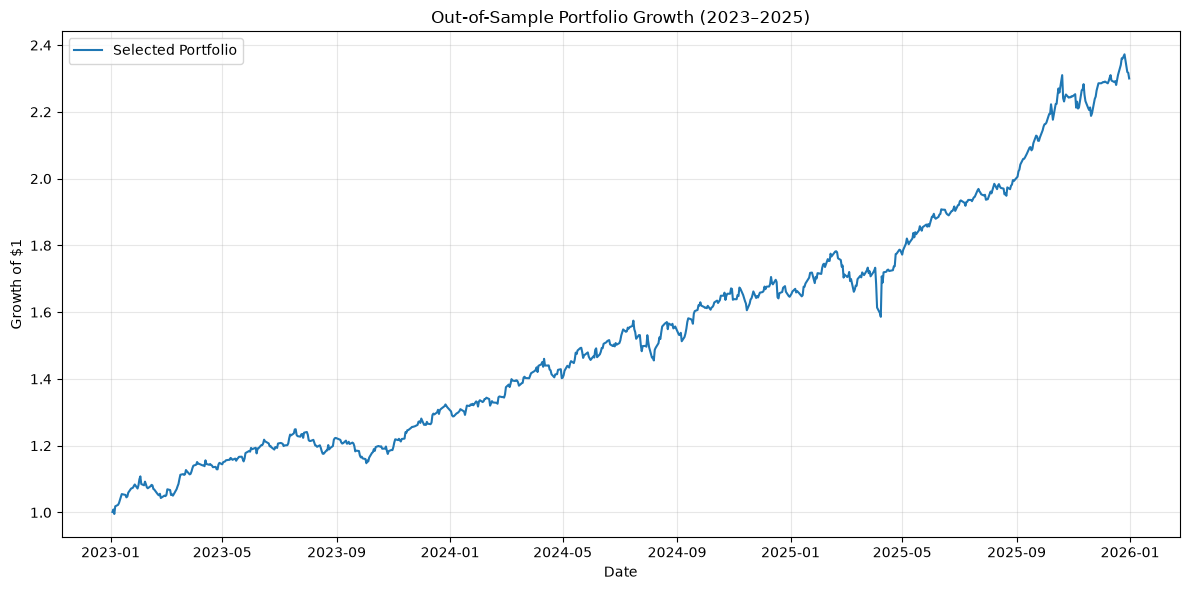

In [102]:
test_cumulative_returns = (1 + test_portfolio_returns).cumprod()

plt.figure(figsize=(12, 6))

plt.plot(
    test_cumulative_returns,
    label="Selected Portfolio"
)

plt.title("Out-of-Sample Portfolio Growth (2023–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Out-of-Sample Comparison with the S&P 500

To evaluate the performance of the optimized portfolio, we compare it with SPY, which tracks the S&P 500.

Both investments are evaluated over the same testing period (2023–2025).

In [103]:
spy_test_returns = testing_returns["SPY"]

spy_annual_return = spy_test_returns.mean() * 252

spy_annual_volatility = spy_test_returns.std() * np.sqrt(252)

spy_sharpe_ratio = spy_annual_return / spy_annual_volatility

print("SPY Benchmark Results")
print("---------------------")
print(f"Annual Return: {spy_annual_return:.2%}")
print(f"Annual Volatility: {spy_annual_volatility:.2%}")
print(f"Sharpe Ratio: {spy_sharpe_ratio:.3f}")

SPY Benchmark Results
---------------------
Annual Return: 21.88%
Annual Volatility: 15.34%
Sharpe Ratio: 1.426


In [104]:
benchmark_comparison = pd.DataFrame({
    "Optimized Portfolio": [
        test_annual_return,
        test_annual_volatility,
        test_sharpe_ratio
    ],
    "SPY": [
        spy_annual_return,
        spy_annual_volatility,
        spy_sharpe_ratio
    ]
}, index=[
    "Annual Return",
    "Annual Volatility",
    "Sharpe Ratio"
])

benchmark_comparison

,Optimized Portfolio,SPY
Annual Return,0.287566,0.218826
Annual Volatility,0.129032,0.153433
Sharpe Ratio,2.228649,1.426203


In [105]:
benchmark_comparison.style.format({
    "Optimized Portfolio": "{:.2%}",
    "SPY": "{:.2%}"
}, subset=pd.IndexSlice[["Annual Return", "Annual Volatility"], :]).format({
    "Optimized Portfolio": "{:.3f}",
    "SPY": "{:.3f}"
}, subset=pd.IndexSlice[["Sharpe Ratio"], :])

,Optimized Portfolio,SPY
Annual Return,28.76%,21.88%
Annual Volatility,12.90%,15.34%
Sharpe Ratio,2.229,1.426


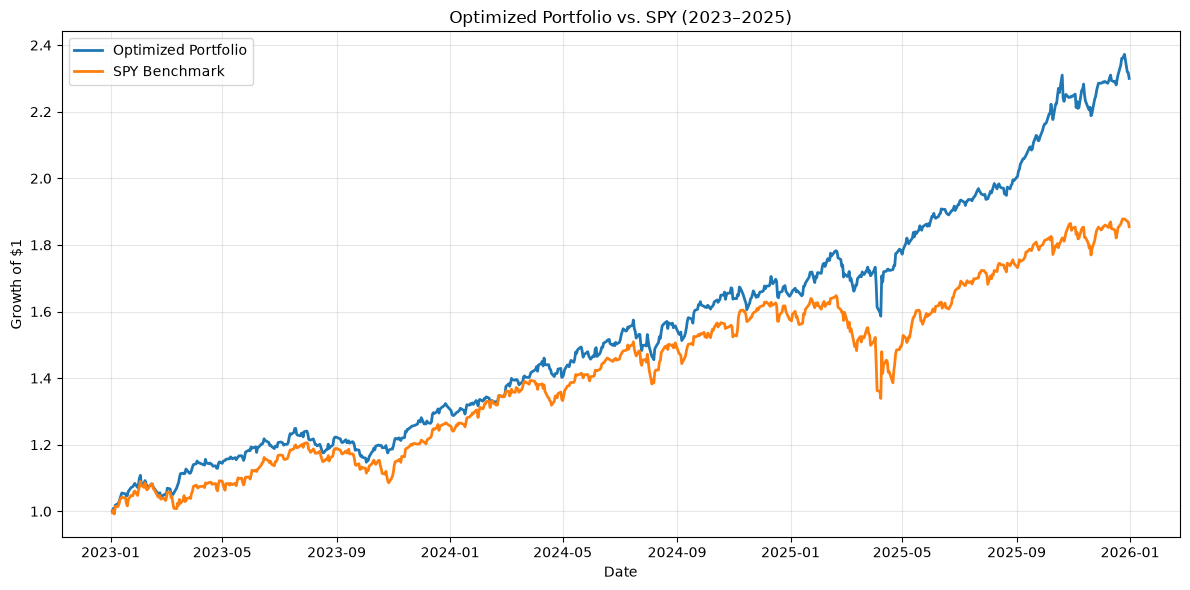

In [106]:
optimized_cumulative = (1 + test_portfolio_returns).cumprod()
spy_cumulative = (1 + spy_test_returns).cumprod()

plt.figure(figsize=(12, 6))

plt.plot(
    optimized_cumulative,
    label="Optimized Portfolio",
    linewidth=2
)

plt.plot(
    spy_cumulative,
    label="SPY Benchmark",
    linewidth=2
)

plt.title("Optimized Portfolio vs. SPY (2023–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Benchmark Comparison: Interpretation

The out-of-sample results show that the optimized portfolio outperformed the SPY benchmark during the 2023–2025 testing period.

The optimized portfolio achieved an annual return of 28.76%, compared with 21.88% for SPY. It also had lower annual volatility (12.90% versus 15.34%) and a higher Sharpe ratio (2.229 versus 1.426).

These results suggest that portfolio optimization and diversification improved risk-adjusted performance during the selected testing period.

However, historical performance does not guarantee future results. The strategy should be tested across additional periods and market conditions.